# Hand-written Digit Recognition from Scratch

## 1. The magic of `nn.Linear`

In [1]:
from torch import nn
linear = nn.Linear(3,5)

In [2]:
linear.state_dict()

OrderedDict([('weight',
              tensor([[-0.3398,  0.1119,  0.3412],
                      [-0.1413, -0.3737,  0.3591],
                      [ 0.4184,  0.1507,  0.5489],
                      [-0.0952, -0.0010,  0.3165],
                      [-0.5401, -0.0345, -0.2269]])),
             ('bias', tensor([-0.5574, -0.3939, -0.2923, -0.1714, -0.5526]))])

We know that a neural network has weights and biases.

Here, `weight` is a two dimensional tensor with 5 elements, `bias` is a one dimensional tensor with 5 elements

In [3]:
from torch import Tensor

input = Tensor([1,2,3]) # 3 numbers
linear(input)

tensor([ 0.3502, -0.2053,  2.0744,  0.6807, -1.8425], grad_fn=<ViewBackward0>)

Output turns into a 1D tensor with 5 numbers!

In [4]:
input = Tensor([[1,2,3], [4,5,6]]) # 2*3 tensor
linear(input)

tensor([[ 0.3502, -0.2053,  2.0744,  0.6807, -1.8425],
        [ 0.6902, -0.6730,  5.4287,  1.3415, -4.2473]],
       grad_fn=<AddmmBackward0>)

Output is a $2*5$ tensor!

In [5]:
input = Tensor([[[1,2,3], [4,5,6]],  [[11,22,33], [44,55,66]]]) # 2*2*3 tensor
output = linear(input)
output

tensor([[[  0.3502,  -0.2053,   2.0744,   0.6807,  -1.8425],
         [  0.6902,  -0.6730,   5.4287,   1.3415,  -4.2473]],

        [[  9.4271,   1.6813,  25.7416,   9.2025, -14.7421],
         [ 13.1666,  -3.4638,  62.6389,  16.4707, -41.1941]]],
       grad_fn=<ViewBackward0>)

Output is a $2*2*5$ tensor!

You can use `.shape` attribute to check the shape of a tensor.

In [6]:
output.shape

torch.Size([2, 2, 5])

Key Takeaway:

The linear transformation will work if:

- the *last* number of the input dimension is the same as the input dimension specified by the `Linear` transformation.

- the *last* number of the output dimension is the same as the output dimension specified by the `Linear` transformation.

During *inference*, the input and output tensors are usually 1D, since the requests are being received one by one.

During *training*, the input and output tensors are usually 2D. The first dimension is `batch_size`, and the second dimension is the original specified input and output size. This enables the model to learn the possible relationships between samples, while also increasing the speed.

## 2. Introduction to MNIST

The author of MNIST is a famous French person in Deep Learning, Yann LeCun. He organized this in 1990s, and he is also the lead creator of JEPA.

The dataset contains:
|Training data|Test data|
|-|-|
|60000|10000|

A total of 70000 black-and-white pictures, each has a hand-written digit on it, with resolution of $28*28$

Let's create the `train_data` and `test_data` objects!

In [7]:
import torchvision

train_data = torchvision.datasets.MNIST(
    root='./dataset',
    train=True,
    download=True
)

test_data = torchvision.datasets.MNIST(
    root='./dataset',
    train=False,
    download=True
)

100%|██████████| 9.91M/9.91M [00:01<00:00, 8.70MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 510kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.98MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.9MB/s]


In [8]:
print(train_data.data.shape)
print(test_data.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


Each picture has a target/label, referring to the actual handwritten digit.

In [9]:
test_data.targets[0]

tensor(7)

Each picture has a 256-degree grey scale.

In [10]:
test_data.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

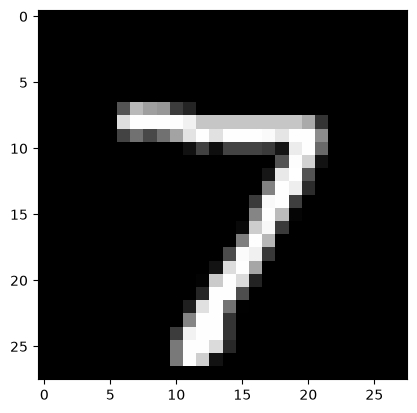

In [14]:
import matplotlib.pyplot as plt

plt.imshow(test_data.data[0], cmap='grey')
plt.show()

## 3. Pre-processing data

We are going to flatten each picture tensor from $28*28$ to a 1D tensor with $784$ elements.

Now, the `view()` method can help us!

In [15]:
flat_test_data = test_data.data.view(10000, 784)

print(test_data.data.shape)
print(flat_test_data.shape)

torch.Size([10000, 28, 28])
torch.Size([10000, 784])


`-1` in `view()` will let PyTorch automatically calculate its dimension.

```Python
flat_test_data = test_data.data.view(-1, 784)
```

will yield the same result.

Another thing to notice:

The 'pixels' living in each tensor is an integer $x \in [0,255]$

They are too large!

But why?

1. Large numbers make convergence harder.

2. Thus inference will fail.

3. Modern AI GPUs are optimized for `fp4` and `fp8` floating point numbers.

In [ ]:
float_flat_test_data = flat_test_data.float() / 255.0
float_flat_test_data.data[0] # the first picture

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

There we have a $10000*784$ input, where 10000 is the number of the model input, 784 is the flattened content of the picture.

## 4. Defining the model

|Model Structure|
|-|
|Linear(784,256)|
|ReLU Activation Function|
|Linear(256,128)|
|ReLU Activation Function|
|Linear(128,10)|
|Output logits|

In [20]:
class MnistModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(784, 256)
        self.relu1 = nn.ReLU()

        self.layer2 = nn.Linear(256, 128)
        self.relu1 = nn.ReLU()

        self.layer3 = nn.Linear(128, 10)

    def forward(self):
        x = self.relu1(self.layer1(x))
        x = self.relu2(self.layer2(x))
        x = self.layer3(x)
        return x

In [21]:
mnist_model = MnistModel()

mnist_model.state_dict()

OrderedDict([('layer1.weight',
              tensor([[ 6.0237e-03, -2.3377e-02,  2.3238e-02,  ...,  1.4766e-02,
                       -1.9842e-03,  2.7749e-02],
                      [-6.4713e-03,  6.8632e-03, -1.3904e-02,  ...,  1.0388e-02,
                       -8.3222e-03,  1.5926e-02],
                      [-2.2776e-02, -1.3141e-02, -1.2915e-02,  ..., -2.2115e-03,
                       -9.7863e-03,  1.9069e-02],
                      ...,
                      [-1.7206e-02, -2.7002e-02,  1.5149e-02,  ...,  2.9740e-02,
                        2.1151e-02,  2.0418e-02],
                      [ 2.3593e-03, -2.3303e-02,  1.8880e-03,  ...,  3.5695e-02,
                       -3.7376e-05,  3.4617e-02],
                      [ 4.6735e-03, -2.3472e-02, -2.0227e-02,  ..., -4.6257e-03,
                       -1.3224e-02,  7.0691e-03]])),
             ('layer1.bias',
              tensor([ 0.0335,  0.0098, -0.0184,  0.0112, -0.0229, -0.0181,  0.0268,  0.0117,
                      -0.0306,